IMPORTACIÓN DE LIBRERIAS NECESARIAS

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error



CREAMOS VARIABLES ALEATORIAS CON ESTACIONALIDAD SEMANAL EN NUMPY

In [3]:
rng = np.random.default_rng(42)

dias = np.arange(1, 61)

dias_semana = [
    "Lunes", "Martes", "Miercoles",
    "Jueves", "Viernes", "Sabado", "Domingo"
]

dia_semana = np.array([
    dias_semana[(dia - 1) % 7]
    for dia in dias
])

# Efecto comercial de cada día
efecto_semanal = {
    "Lunes": -8,
    "Martes": -5,
    "Miercoles": 0,
    "Jueves": 3,
    "Viernes": 8,
    "Sabado": 18,
    "Domingo": 10
}

ventas = (
    100
    + dias * 2.5
    + np.array([efecto_semanal[d] for d in dia_semana])
    + rng.normal(0, 10, 60)
)

df = pd.DataFrame({
    "dia": dias,
    "dia_semana": dia_semana,
    "ventas": ventas
})

df.head(10)

,dia,dia_semana,ventas
0,1,Lunes,97.547171
1,2,Martes,89.600159
2,3,Miercoles,115.004512
3,4,Jueves,122.405647
4,5,Viernes,100.989648
5,6,Sabado,119.978205
6,7,Domingo,128.778404
7,8,Lunes,108.837574
8,9,Martes,117.331988
9,10,Miercoles,116.469561


One-Hot Encoding

In [8]:
df_modelo = pd.get_dummies(
    df,
    columns=["dia_semana"],
    dtype=int,
    drop_first=True
)

df_modelo.head(7)

,dia,ventas,dia_semana_Jueves,dia_semana_Lunes,dia_semana_Martes,dia_semana_Miercoles,dia_semana_Sabado,dia_semana_Viernes
0,1,97.547171,0,1,0,0,0,0
1,2,89.600159,0,0,1,0,0,0
2,3,115.004512,0,0,0,1,0,0
3,4,122.405647,1,0,0,0,0,0
4,5,100.989648,0,0,0,0,0,1
5,6,119.978205,0,0,0,0,1,0
6,7,128.778404,0,0,0,0,0,0


SEPARAMOS LOS CONJUNTOS EN 2 MODELOS PARA COMPARARLOS

In [9]:

# Modelo 1: solamente el día
X1 = df[["dia"]]

# Modelo 2: día + día de la semana
X2 = pd.get_dummies(
    df[["dia", "dia_semana"]],
    columns=["dia_semana"],
    drop_first=True,
    dtype=int
)

# Misma división para ambos
X1_train, X1_test = X1.iloc[:45], X1.iloc[45:]
X2_train, X2_test = X2.iloc[:45], X2.iloc[45:]

y_train = df["ventas"].iloc[:45]
y_test = df["ventas"].iloc[45:]





AHORA VAMOS A UTILIZAR LinearRegression de Scikit-learn

In [10]:
# Entrenamiento
modelo1 = LinearRegression().fit(X1_train, y_train)
modelo2 = LinearRegression().fit(X2_train, y_train)

# Predicciones
pred1 = modelo1.predict(X1_test)
pred2 = modelo2.predict(X2_test)

OBSERVAMOS LOS RESULTADOS DEL PRIMER MODELO

In [13]:
# Modelo 1
print("\n--- MODELO 1: SOLAMENTE DIA ---")
print("Intercepto:", modelo1.intercept_)

coeficientes1 = pd.DataFrame({
    "Variable": X1.columns,
    "Coeficiente": modelo1.coef_
})

display(coeficientes1)



--- MODELO 1: SOLAMENTE DIA ---
Intercepto: 101.5692639229911


,Variable,Coeficiente
0,dia,2.594093


AHORA CON EL SEGUNDO

In [14]:
# Modelo 2
print("\n--- MODELO 2: DIA + DIA DE LA SEMANA ---")
print("Intercepto:", modelo2.intercept_)

coeficientes2 = pd.DataFrame({
    "Variable": X2.columns,
    "Coeficiente": modelo2.coef_
})

display(coeficientes2)


--- MODELO 2: DIA + DIA DE LA SEMANA ---
Intercepto: 112.67833978663313


,Variable,Coeficiente
0,dia,2.567197
1,dia_semana_Jueves,-12.453311
2,dia_semana_Lunes,-21.226313
3,dia_semana_Martes,-19.430297
4,dia_semana_Miercoles,-12.105627
5,dia_semana_Sabado,2.368728
6,dia_semana_Viernes,-7.037895


EVALUAMOS AL MODELO Y CALCULAMOS EL ERROR ABSOLUTO MEDIO (MAE) EN CADA UNO

In [16]:
# Evaluación
print("MAE modelo 1:", mean_absolute_error(y_test, pred1))
print("MAE modelo 2:", mean_absolute_error(y_test, pred2))

MAE modelo 1: 8.668312962292134
MAE modelo 2: 6.448392101383316


VAMOS A COMPARAR LA VENTAS REALES CON LAS QUE PREDIJO EL MODELO 

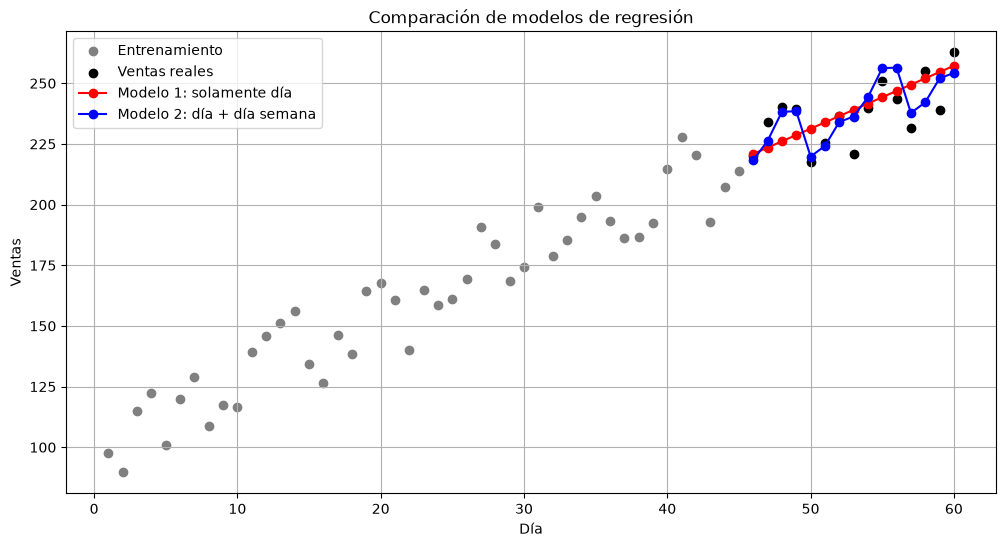

In [17]:
plt.figure(figsize=(12, 6))

# Datos de entrenamiento
plt.scatter(
    X1_train["dia"],
    y_train,
    label="Entrenamiento",
    color="gray"
)

# Ventas reales del conjunto de prueba
plt.scatter(
    X1_test["dia"],
    y_test,
    label="Ventas reales",
    color="black"
)

# Predicciones del modelo 1
plt.plot(
    X1_test["dia"],
    pred1,
    marker="o",
    color="red",
    label="Modelo 1: solamente día"
)

# Predicciones del modelo 2
plt.plot(
    X2_test["dia"],
    pred2,
    marker="o",
    color="blue",
    label="Modelo 2: día + día semana"
)

plt.xlabel("Día")
plt.ylabel("Ventas")
plt.title("Comparación de modelos de regresión")

plt.legend()
plt.grid()
plt.show()

AHORA VAMOS A PREDECIR LOS DÍAS 61 AL 67 PARA LOS 2 MODELOS

In [18]:
# Días futuros
dias_futuros = np.arange(61, 68)

# Identificar el día de la semana
dias_semana_futuros = [
    dias_semana[(dia - 1) % 7]
    for dia in dias_futuros
]

df_futuro = pd.DataFrame({
    "dia": dias_futuros,
    "dia_semana": dias_semana_futuros
})


# MODELO 1: solamente día
X_futuro1 = df_futuro[["dia"]]

ventas_futuras1 = modelo1.predict(X_futuro1)


# MODELO 2: día + día de la semana
X_futuro2 = pd.get_dummies(
    df_futuro,
    columns=["dia_semana"],
    drop_first=True,
    dtype=int
)

# Alinear las columnas con las utilizadas durante el entrenamiento
X_futuro2 = X_futuro2.reindex(
    columns=X2.columns,
    fill_value=0
)

ventas_futuras2 = modelo2.predict(X_futuro2)


# Comparación de predicciones
df_futuro["modelo_1"] = ventas_futuras1
df_futuro["modelo_2"] = ventas_futuras2

df_futuro

,dia,dia_semana,modelo_1,modelo_2
0,61,Viernes,259.808956,262.239450
1,62,Sabado,262.403050,274.213270
2,63,Domingo,264.997143,274.411739
3,64,Lunes,267.591236,255.752622
4,65,Martes,270.185330,260.115835
5,66,Miercoles,272.779423,270.007703
6,67,Jueves,275.373516,272.227215


VISUALIZAMOS EL RESULTADO

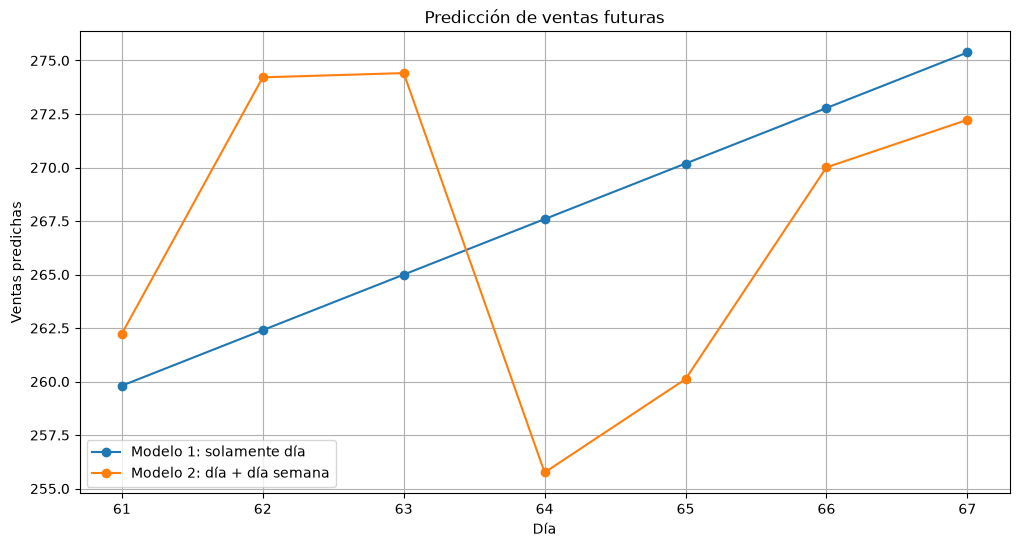

In [19]:
plt.figure(figsize=(12, 6))

plt.plot(
    df_futuro["dia"],
    df_futuro["modelo_1"],
    marker="o",
    label="Modelo 1: solamente día"
)

plt.plot(
    df_futuro["dia"],
    df_futuro["modelo_2"],
    marker="o",
    label="Modelo 2: día + día semana"
)

plt.xlabel("Día")
plt.ylabel("Ventas predichas")
plt.title("Predicción de ventas futuras")

plt.legend()
plt.grid()
plt.show()